## Task Three of the Detheon ML and DS Internship
### Abdul-Azeez Mahmud Gambo | mahmudabdulazeez9@gmail.com

### Detailed Problem Statement & Requirements
Train an ensemble machine learning model to predict customer churn using telecom subscription records. Preprocess categorical features using OneHotEncoder, balance class distributions with SMOTE or class weighting, train Random Forest and XGBoost classifiers, and evaluate ROC-AUC curve (>80%).

### Suggested Technical Approach
1. Load the Telco Customer Churn dataset.
2. Convert TotalCharges to numeric and handle nulls.
3. Balance target classes using SMOTE or scale_pos_weight.
4. Train RandomForestClassifier and XGBClassifier with cross-validation.
5. Plot ROC-AUC curves and extract top 10 most influential feature importances.

In [139]:
!pip install xgboost

In [140]:
!pip install imblearn

In [141]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImPipeline  # For SMOTE
from sklearn.pipeline import Pipeline as SkPipeline  # For XGBoost
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImPipeline
from sklearn.impute import SimpleImputer

##### 1. Load the Telco Customer Churn dataset and analysing it.
This is to check the datatypes and to verify if there is any null values

In [142]:
#Loading the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

In [143]:
# Previewing the fist 5 rows 
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [144]:
# Checking the datatypes, and weither there is any null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [145]:
# Counting the null values if there 
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

#### 2. Convert TotalCharges to numeric and handle nulls.

In [146]:
# Converting TotalCharges column to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [147]:
[df["TotalCharges"].isnull() == False]

[0       True
 1       True
 2       True
 3       True
 4       True
         ... 
 7038    True
 7039    True
 7040    True
 7041    True
 7042    True
 Name: TotalCharges, Length: 7043, dtype: bool]

##### TotalCharges has non-null values length as 7043, which is the equal to the total number of columns
Therefore, TotalCharges has no null value

In [148]:
# CustomerID column is not a predictive field, so we can drop it
df.drop(columns="customerID", inplace=True)

In [149]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [150]:
#Converting target variable and checking the sum of each of the occurence of 0s and 1s
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [151]:
(df["Churn"] == 1).sum(), (df["Churn"] == 0).sum()

(np.int64(1869), np.int64(5174))

In [152]:
1869 + 5174

7043

#### Feature Categorization & Stratified Splitting
This is to prevent data leakage prior to preprocessing.

- Divide columns into numeric and categorical feature sets.
  
- Perform a 80/20 stratified split to preserve class ratios between training and evaluation sets.

In [153]:
# Identifying Numerical and Categorical Features
X = df.drop(columns=["Churn"])
y = df["Churn"]

categorical_cols = X.select_dtypes(include=['string']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

#### Building Preprocessing & Ensembling Pipelines
Integrating OneHotEncoder, Scaling, and SMOTE

- Preprocessing Pipeline: Apply OneHotEncoder(handle_unknown='ignore') to categorical features and StandardScaler to numerical features.

- Imbalance Treatment: Integrate SMOTE inside the imblearn.pipeline.Pipeline to ensure synthetic samples are generated only on the training folds during cross-validation, preventing data leakage.

In [154]:
# 1. ROBUST PREPROCESSING SETUP
# We move specific imputers inside the column transformer blocks
numerical_transformer = SkPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Handles numerical NaNs safely
    ('scaler', StandardScaler())
])

categorical_transformer = SkPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')), # Handles text NaNs safely
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown="ignore")) # Removed drop='first' to allow handle_unknown
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols)
    ]
)

# 2. RANDOM FOREST PIPELINE WITH SMOTE
rf_pipeline = ImPipeline(steps=[
    ("preprocessor", preprocessor), # Preprocessing handles imputation completely now
    ("smote", SMOTE(random_state=42)),
    ("classifier", RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42))
])

# 3. XGBOOST PIPELINE (XGBoost natively handles missing data, but preprocessor handles encoding)
scale_pos_weight_val = (len(y_train) - sum(y_train)) / sum(y_train)

xgb_pipeline = SkPipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight_val,
        eval_metric="logloss",
        random_state=42
    ))
])


#### 4.Cross-Validation & Model Training:

Train classifiers and validate performance.
- Evaluating both models using 5-Fold Stratified Cross-Validation with roc_auc scoring.
  
- Fit final models on the entire training dataset.

In [155]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Evaluating Random Forest via Cross-Validation
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=cv, scoring="roc_auc_ovr")
print(f"Random Forest CV ROC-AUC Score: {rf_cv_scores.mean():.4f} +/- {rf_cv_scores.std():.4f}")

# Evaluating XGBoost via Cross-Validation
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=cv, scoring="roc_auc")
print(f"XGBoost CV ROC-AUC Score: {xgb_cv_scores.mean():.4f} +/- {xgb_cv_scores.std():.4f}")

# Training Final Models
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

Random Forest CV ROC-AUC Score: 0.8411 +/- 0.0083
XGBoost CV ROC-AUC Score: 0.8485 +/- 0.0109


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

#### 5.Model Evaluation & Feature Importance Extraction:
Verifying ROC-AUC score.

80% and inspect influential factors">
- Generate predicted probabilities for the test set.
- Plot ROC Curves for comparison.
- Extract and plot the top 10 feature importances from both models.


--- Test Set Results ---
Random Forest ROC-AUC Score: 0.8363
XGBoost ROC-AUC Score: 0.8447


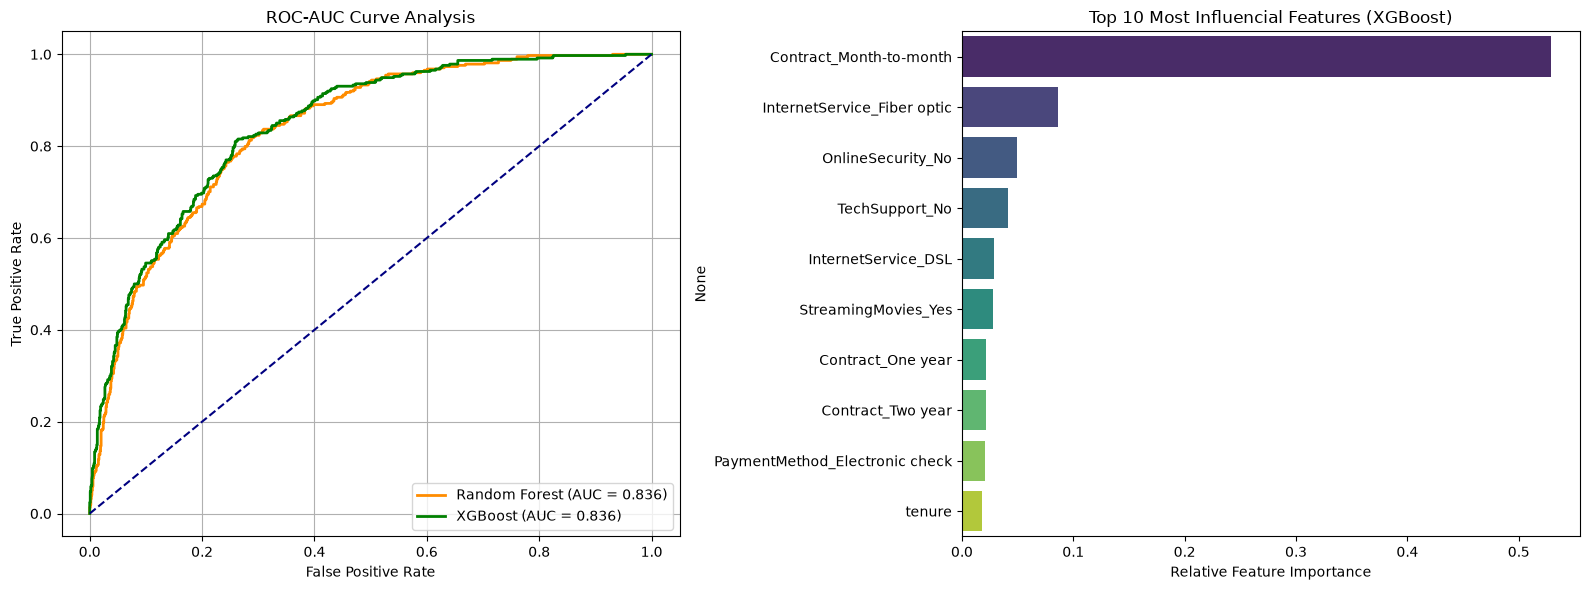

In [156]:
# Test Predictions (Probabilities)
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]
xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

print(f"\n--- Test Set Results ---")
print(f"Random Forest ROC-AUC Score: {rf_auc:.4f}")
print(f"XGBoost ROC-AUC Score: {xgb_auc:.4f}")

#Feature Names Extraction from Preprocessor
ohe_feature_names = rf_pipeline.named_steps["preprocessor"]\
    .named_transformers_["cat"]\
    .get_feature_names_out(categorical_cols)

all_feature_names = list(numerical_cols) + list(ohe_feature_names)

# Plotting ROC Curves & Top 10 Feature Importances
fig, axes = plt.subplots(1,2, figsize=(16, 6))

# Subplot 1: ROC-Curves
rf_fqr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

axes[0].plot(rf_fqr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})", color="darkorange", lw=2)
axes[0].plot(xgb_fpr, xgb_tpr, label=f"XGBoost (AUC = {rf_auc:.3f})", color="green", lw=2)
axes[0].plot([0, 1], [0, 1], color="navy", linestyle="--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC-AUC Curve Analysis")
axes[0].legend(loc="lower right")
axes[0].grid(True)

# Subplot 2: Top 10 Feature Importances (XGBoost)
xgb_importances = xgb_pipeline.named_steps["classifier"].feature_importances_
feat_imp = pd.Series(xgb_importances, index=all_feature_names).sort_values(ascending=False).head(10)

sns.barplot(x=feat_imp.values, y=feat_imp.index, ax=axes[1], hue=feat_imp.index, palette="viridis")
axes[1].set_title("Top 10 Most Influencial Features (XGBoost)")
axes[1].set_xlabel("Relative Feature Importance")

plt.tight_layout()
plt.show()